# BS49903 · DS/AI for Biology
## Week 4 Practice Notebook — Logistic Regression

Covers Week 4-1 (logistic regression, cross-entropy loss, regularization, evaluation).

In [1]:
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

np.set_printoptions(precision=3, suppress=True)

---
# Part 1 · The data

569 biopsies, 30 features measured from cell nuclei, and one label per biopsy.

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target          # (569, 30), 0 = malignant, 1 = benign

print("shape:", X.shape)
print("malignant:", (y == 0).sum(), "  benign:", (y == 1).sum())

df = pd.DataFrame(X, columns=data.feature_names)
df["target"] = y
df.head()

shape: (569, 30)
malignant: 212   benign: 357


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Each row is one fine-needle aspirate from one patient's breast mass; the 30 columns summarise
the many nuclei in that sample (mean / error / worst of 10 measurements). Note the convention:
**0 is malignant, 1 is benign.** scikit-learn calls class 1 "positive", so "positive" will mean
benign unless we say otherwise.

### 1.1 Split into training and test sets first

The test set has to behave like samples we have never seen. `stratify=y` keeps the
malignant/benign ratio the same in both halves.

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

print("train:", X_tr.shape, "  test:", X_te.shape)
print("benign fraction   train:", round(y_tr.mean(), 3), "  test:", round(y_te.mean(), 3))

train: (398, 30)   test: (171, 30)
benign fraction   train: 0.628   test: 0.626


---
# Part 2 · Standardization

### 2.1 Features live on wildly different scales

In [4]:
df[["mean area", "mean radius", "mean fractal dimension"]].agg(["mean", "std"]).round(3)

,mean area,mean radius,mean fractal dimension
mean,654.889,14.127,0.063
std,351.914,3.524,0.007


"mean area" is in the hundreds, "mean fractal dimension" is around 0.06. The regularization
penalty treats every weight equally, so without rescaling it would shrink the small-scale
features for no reason, and the fitted weights could not be compared with each other.

### 2.2 Subtract the mean, divide by the SD — using the training set only

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

`fit` learns μ and σ from the training data; `transform` applies them to both halves.

In [6]:
scaler = StandardScaler().fit(X_tr)                  # fit on the training set only
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

print("train  mean of first 3 features:", X_tr_s.mean(axis=0)[:3], "  sd:", X_tr_s.std(axis=0)[:3])
print("test   mean of first 3 features:", X_te_s.mean(axis=0)[:3], "  sd:", X_te_s.std(axis=0)[:3])

train  mean of first 3 features: [-0. -0.  0.]   sd: [1. 1. 1.]
test   mean of first 3 features: [0.021 0.055 0.021]   sd: [0.907 1.023 0.908]


The training columns are exactly mean 0, SD 1. The test columns are only approximately so —
that is correct, because they were scaled with the training set's μ and σ.

---
# Part 3 · Logistic regression

### 3.1 The sigmoid function

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

It maps any number to (0, 1) and crosses 0.5 at z = 0.

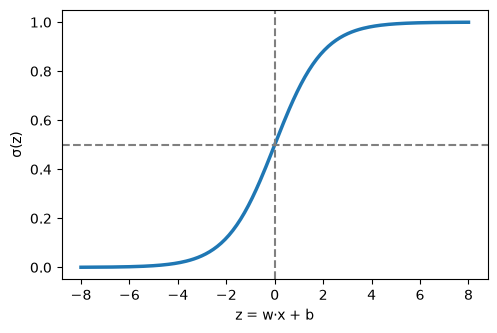

[0.047 0.5   0.953]


In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
plt.figure(figsize=(5.5, 3.5))
plt.plot(z, sigmoid(z), lw=2.5)
plt.axhline(0.5, ls="--", color="gray"); plt.axvline(0, ls="--", color="gray")
plt.xlabel("z = w·x + b"); plt.ylabel("σ(z)"); plt.show()

print(sigmoid(np.array([-3.0, 0.0, 3.0])))

### 3.2 Three steps: logit → sigmoid → threshold

1. compute a linear score, $z = \mathbf{w}\cdot\mathbf{x} + b$
2. turn it into a probability, $\hat p = \sigma(z) = P(y=1 \mid \mathbf{x})$
3. predict class 1 if $\hat p \ge 0.5$, i.e. if $z \ge 0$

The only things that are learned are **w** (one weight per feature) and **b**.

In [8]:
clf = LogisticRegression(C=1.0)
clf.fit(X_tr_s, y_tr)

print("w shape:", clf.coef_.shape, "  b:", clf.intercept_)
print("train accuracy:", round(clf.score(X_tr_s, y_tr), 3))
print("test  accuracy:", round(clf.score(X_te_s, y_te), 3))

w shape: (1, 30)   b: [0.343]
train accuracy: 0.992
test  accuracy: 0.959


### 3.3 `predict_proba` is just the sigmoid of the logit

Reproduce it by hand for one test sample that sits near the decision boundary.

In [9]:
w, b = clf.coef_[0], clf.intercept_[0]

i = 137
z_i = w @ X_te_s[i] + b                 # step 1: logit
p_i = sigmoid(z_i)                      # step 2: probability of class 1 (benign)

print("by hand:        z =", round(z_i, 3), "  P(benign) =", round(p_i, 3))
print("predict_proba:  ", clf.predict_proba(X_te_s[i:i+1])[0], "  <- [P(malignant), P(benign)]")
print("predict:        ", clf.predict(X_te_s[i:i+1])[0], "   true label:", y_te[i])

by hand:        z = 0.41   P(benign) = 0.601
predict_proba:   [0.399 0.601]   <- [P(malignant), P(benign)]
predict:         1    true label: 1


In [10]:
# all test samples at once: the decision rule is just the sign of z
z_all = X_te_s @ w + b
print("(z >= 0) agrees with predict() ?", np.array_equal((z_all >= 0).astype(int), clf.predict(X_te_s)))

(z >= 0) agrees with predict() ? True


### 3.4 Every training sample on the fitted sigmoid

Each biopsy's 30 features collapse to a single number z. Plot the training samples at their z,
with malignant at y = 0 and benign at y = 1.

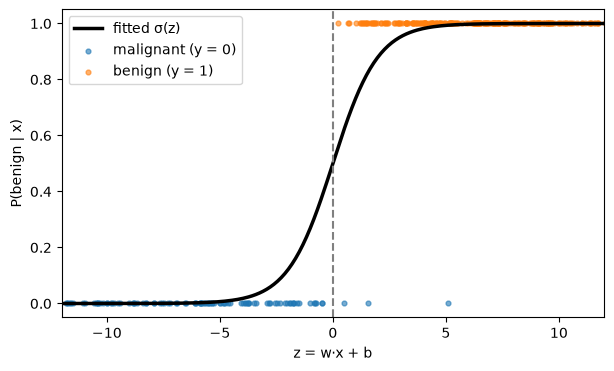

training samples on the wrong side of z = 0: 3 of 398
training samples with z < -12 (off the left edge): 50


In [11]:
z_tr = X_tr_s @ w + b

plt.figure(figsize=(7, 4))
zz = np.linspace(-12, 12, 300)
plt.plot(zz, sigmoid(zz), color="k", lw=2.5, label="fitted σ(z)")
plt.scatter(z_tr[y_tr == 0], np.zeros((y_tr == 0).sum()), s=12, alpha=0.6, label="malignant (y = 0)")
plt.scatter(z_tr[y_tr == 1], np.ones((y_tr == 1).sum()),  s=12, alpha=0.6, label="benign (y = 1)")
plt.axvline(0, ls="--", color="gray")
plt.xlim(-12, 12); plt.xlabel("z = w·x + b"); plt.ylabel("P(benign | x)"); plt.legend(); plt.show()

wrong = ((z_tr >= 0) != (y_tr == 1)).sum()
print("training samples on the wrong side of z = 0:", wrong, "of", len(y_tr))
print("training samples with z < -12 (off the left edge):", (z_tr < -12).sum())

Only a handful of training points sit on the wrong side of z = 0 — that is what 99% training
accuracy looks like. Many malignant samples are far off to the left: the model is very sure about them.

---
# Part 4 · How the model is fitted: cross-entropy loss

### 4.1 The loss of one sample

$$\ell(y, \hat p) = -\,y \log \hat p \;-\; (1-y) \log (1 - \hat p)$$

Confident and right costs almost nothing. Confident and wrong is enormous.

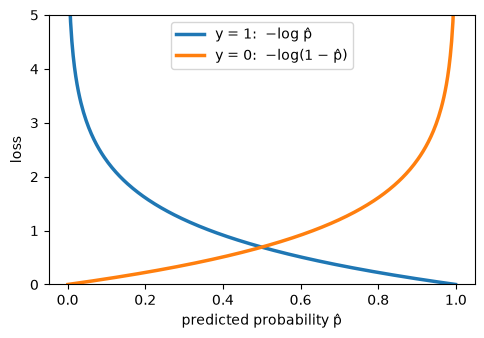

p̂ = 0.5 (coin flip):      0.693
right, p̂ = 0.99:          0.01
wrong, p̂ = 0.01:          4.605


In [13]:
p = np.linspace(0.001, 0.999, 300)
plt.figure(figsize=(5.5, 3.5))
plt.plot(p, -np.log(p),     lw=2.5, label="y = 1:  −log p̂")
plt.plot(p, -np.log(1 - p), lw=2.5, label="y = 0:  −log(1 − p̂)")
plt.xlabel("predicted probability p̂"); plt.ylabel("loss"); plt.ylim(0, 5); plt.legend(); plt.show()

print("p̂ = 0.5 (coin flip):     ", round(-np.log(0.5), 3))
print("right, p̂ = 0.99:         ", round(-np.log(0.99), 3))
print("wrong, p̂ = 0.01:         ", round(-np.log(0.01), 3))

### 4.2 The total loss is the sum over samples

$$L = -\sum_i \big( y_i \log \hat p_i + (1 - y_i) \log (1 - \hat p_i) \big)$$

Compute the mean loss on the test set by hand and check it against scikit-learn.

In [14]:
from sklearn.metrics import log_loss

p_hat = clf.predict_proba(X_te_s)[:, 1]                    # P(benign)
loss_by_hand = -np.mean(y_te * np.log(p_hat) + (1 - y_te) * np.log(1 - p_hat))

print("by hand:", round(loss_by_hand, 4), "   sklearn log_loss:", round(log_loss(y_te, p_hat), 4))

by hand: 0.0846    sklearn log_loss: 0.0846


Fitting means finding the **w** and b that make this number as small as possible on the training
set. There is no closed form; scikit-learn uses gradient descent (the `lbfgs` solver).

---
# Part 5 · Overfitting and regularization

### 5.1 The regularized objective

$$L = -\sum_i \big( y_i \log \hat p_i + (1 - y_i)\log(1-\hat p_i) \big) + \lambda \lVert \mathbf{w} \rVert_2^2,
\qquad \lambda = \frac{1}{2C}$$

Large weights can fit individual noisy points and make every decision overconfident.
The penalty makes large weights expensive. In scikit-learn the knob is `C`: **large C = weak
regularization, small C = strong**.

### 5.2 Sweep C and watch three things

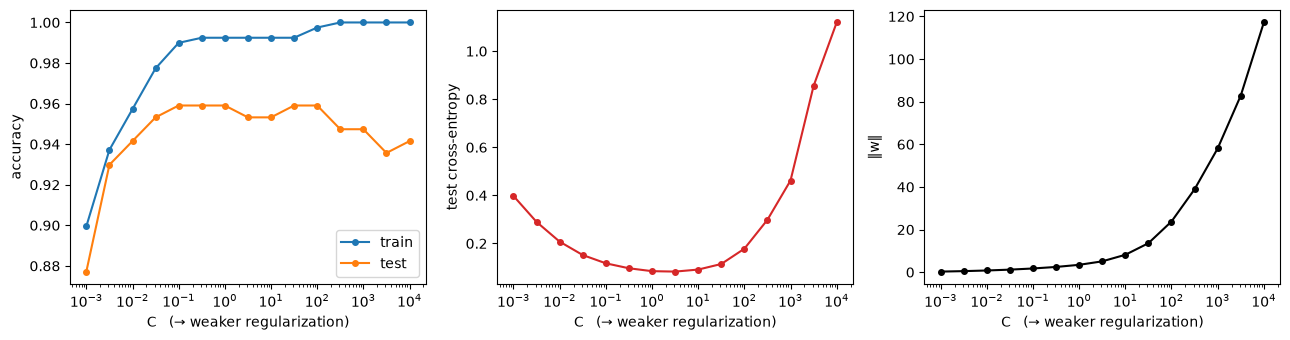

In [15]:
Cs = np.logspace(-3, 4, 15)
train_acc, test_acc, test_loss, w_norm = [], [], [], []
for C in Cs:
    m = LogisticRegression(C=C, max_iter=5000).fit(X_tr_s, y_tr)
    train_acc.append(m.score(X_tr_s, y_tr))
    test_acc.append(m.score(X_te_s, y_te))
    test_loss.append(log_loss(y_te, m.predict_proba(X_te_s)))
    w_norm.append(np.linalg.norm(m.coef_))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].semilogx(Cs, train_acc, "o-", ms=4, label="train"); axes[0].semilogx(Cs, test_acc, "o-", ms=4, label="test")
axes[0].set_ylabel("accuracy"); axes[0].legend()
axes[1].semilogx(Cs, test_loss, "o-", ms=4, color="C3"); axes[1].set_ylabel("test cross-entropy")
axes[2].semilogx(Cs, w_norm, "o-", ms=4, color="k");     axes[2].set_ylabel("‖w‖")
for ax in axes: ax.set_xlabel("C   (→ weaker regularization)")
plt.tight_layout(); plt.show()

In [16]:
pd.DataFrame({"C": Cs, "train acc": train_acc, "test acc": test_acc, "test loss": test_loss, "‖w‖": w_norm}).round(3)

,C,train acc,test acc,test loss,‖w‖
0,0.001,0.899,0.877,0.398,0.277
1,0.003,0.937,0.930,0.289,0.494
2,0.010,0.957,0.942,0.207,0.793
3,0.032,0.977,0.953,0.152,1.198
4,0.100,0.990,0.959,0.117,1.738
5,0.316,0.992,0.959,0.097,2.456
6,1.000,0.992,0.959,0.085,3.453
7,3.162,0.992,0.953,0.083,5.085
8,10.000,0.992,0.953,0.091,8.159
9,31.623,0.992,0.959,0.114,13.597


Read the three panels together.

- **Accuracy**: training accuracy climbs to 1.0 and stays there; test accuracy peaks and then drifts
  down. The gap is overfitting.
- **Cross-entropy**: keeps rising for large C even where the accuracy is flat. The model makes the
  same calls with more confidence, and its confident errors cost more.
- **‖w‖**: grows without bound. The weights are what the penalty controls; everything else follows.

Left of the peak the model is too rigid (high **bias**, underfitting); right of it, too sensitive to
the particular training sample (high **variance**, overfitting).

---
# Part 6 · Evaluation

### 6.1 The confusion matrix

Decide which class is *positive*. Here the natural choice is **malignant** (the thing we screen
for), which is class 0 — so tell scikit-learn with `labels=[0, 1]` and `pos_label=0`.

In [17]:
from sklearn.metrics import confusion_matrix

y_pred = clf.predict(X_te_s)                                   # the C = 1 model from Part 3
cm = confusion_matrix(y_te, y_pred, labels=[0, 1])             # rows: truth, columns: prediction
pd.DataFrame(cm, index=["truth malignant", "truth benign"], columns=["pred malignant", "pred benign"])

,pred malignant,pred benign
truth malignant,61,3
truth benign,4,103


In [18]:
TP = cm[0, 0]   # malignant called malignant   correctly predicted
FN = cm[0, 1]   # malignant called benign      missed
FP = cm[1, 0]   # benign called malignant      false alarm
TN = cm[1, 1]   # benign called benign         correctly missed

print(f"TP = {TP}   FN = {FN}   FP = {FP}   TN = {TN}")

TP = 61   FN = 3   FP = 4   TN = 103


### 6.2 Accuracy, precision, recall, F1

$$\text{Accuracy} = \frac{TP + TN}{N_{all}} \qquad
\text{Precision} = \frac{TP}{TP + FP} \qquad
\text{Recall} = \frac{TP}{TP + FN} \qquad
F1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy  = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)        # how accurate are the positive calls?
recall    = TP / (TP + FN)        # how many of the real positives did we catch?
f1        = 2 * precision * recall / (precision + recall)

print(f"accuracy   {accuracy:.3f}   sklearn {accuracy_score(y_te, y_pred):.3f}")
print(f"precision  {precision:.3f}   sklearn {precision_score(y_te, y_pred, pos_label=0):.3f}")
print(f"recall     {recall:.3f}   sklearn {recall_score(y_te, y_pred, pos_label=0):.3f}")
print(f"F1         {f1:.3f}   sklearn {f1_score(y_te, y_pred, pos_label=0):.3f}")

accuracy   0.959   sklearn 0.959
precision  0.938   sklearn 0.938
recall     0.953   sklearn 0.953
F1         0.946   sklearn 0.946


### 6.3 The threshold is a choice

Lowering the threshold on P(malignant) catches more cancers (higher recall) and raises more
false alarms (lower precision).

In [21]:
p_mal = clf.predict_proba(X_te_s)[:, 0]          # P(malignant)
is_mal = (y_te == 0).astype(int)

for t in [0.9, 0.5, 0.2, 0.05]:
    call = (p_mal >= t).astype(int)
    print(f"threshold {t:4.2f}   recall {recall_score(is_mal, call):.3f}   "
          f"precision {precision_score(is_mal, call):.3f}   false alarms {((call == 1) & (is_mal == 0)).sum()}")

threshold 0.90   recall 0.844   precision 1.000   false alarms 0
threshold 0.50   recall 0.953   precision 0.938   false alarms 4
threshold 0.20   recall 0.969   precision 0.899   false alarms 7
threshold 0.05   recall 1.000   precision 0.780   false alarms 18


### 6.4 Precision–recall curve and average precision

Sweep the threshold from 1 to 0 and record precision and recall at every step. The area under the
curve is the **average precision (AP)**; its baseline is the prevalence, not 0.5.

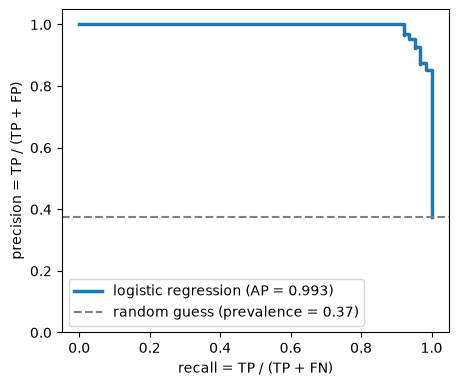

In [22]:
from sklearn.metrics import precision_recall_curve, average_precision_score

P, R, T = precision_recall_curve(is_mal, p_mal)
ap = average_precision_score(is_mal, p_mal)

plt.figure(figsize=(5, 4.2))
plt.step(R, P, where="post", lw=2.5, label=f"logistic regression (AP = {ap:.3f})")
plt.axhline(is_mal.mean(), ls="--", color="gray", label=f"random guess (prevalence = {is_mal.mean():.2f})")
plt.xlabel("recall = TP / (TP + FN)"); plt.ylabel("precision = TP / (TP + FP)")
plt.ylim(0, 1.05); plt.legend(loc="lower left"); plt.show()

Top left: a high threshold, few positive calls, all of them right. Bottom right: a threshold of 0,
everything called positive, precision falls to the prevalence. For a screening test you choose the
recall you need and read off the precision you must live with.